# Classification analysis (titanic data)

## Libraries and settings

In [1]:
# Libraries
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image

from sklearn import tree
from sklearn.metrics import RocCurveDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

# Show version of scikit-learn
import sklearn
sklearn.__version__

/home/claude/build


'1.9.1'

## Import titanic data

In [2]:
# Read and select variables
df_titanic_orig = pd.read_csv("titanic.csv", sep=",", encoding="utf-8")

# Number of rows and columns
print(df_titanic_orig.shape)

# First records
df_titanic_orig.head(5)

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Variable description

- PassengerId passenger identification number
- Survival survival status (0 = No; 1 = Yes)
- Pclass passenger class (1 = 1st; 2 = 2nd; 3 = 3rd)
- Name name
- Sex sex
- Age age 
- SibSp number of siblings/spouses aboard
- Parch number of parents/children aboard
- Ticket ticket number
- Fare passenger fare (British pound)
- Cabin cabin
- Embarked port of embarkation (C = Cherbourg; Q = Queenstown; S = Southampton)

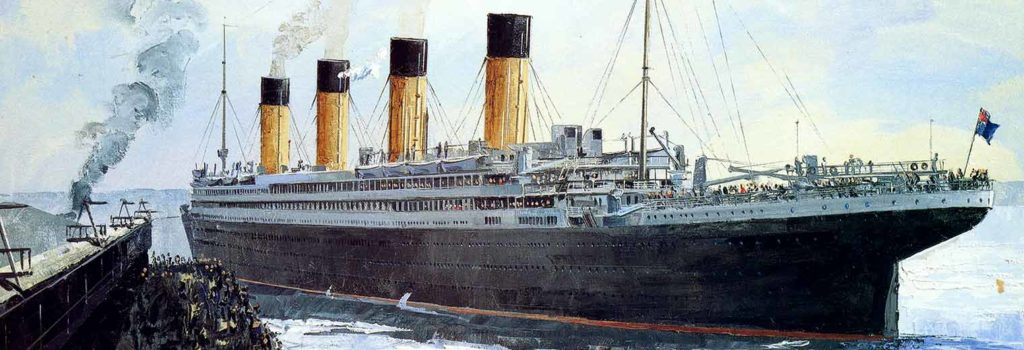

In [3]:
Image("img.jpg", width='800')

## Count and remove missing values

In [4]:
# Count missing values
print(df_titanic_orig.isna().sum())

# Remove missing values
df_titanic = df_titanic_orig.dropna(subset=['Survived', 'Sex', 'Age', 'Pclass', 'Fare'])

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


## Barchart survival status count by gender

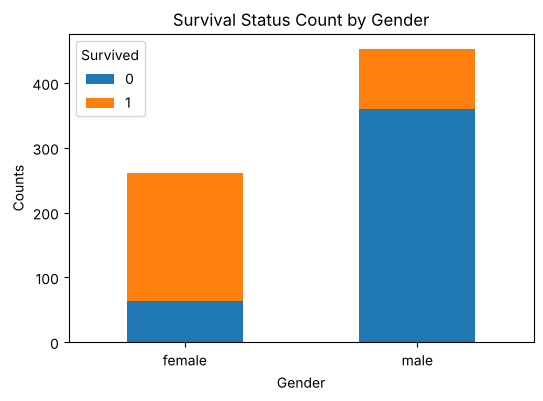

In [5]:
# Create a pivot table
table = df_titanic[['Sex', 'Survived']].pivot_table(index='Sex', 
                                        columns=['Survived'], 
                                        aggfunc=len)

# Plot a stacked bar chart
table.plot(kind='bar', 
           stacked=True, 
           ylabel='Counts', 
           xlabel='Gender',
           title='Survival Status Count by Gender', 
           rot=0,
           figsize=(6,4))

plt.show()

## Pivot table

In [6]:
# Using pivot_table to reshape the data and calculate means 
pd.pivot_table(df_titanic[['Survived',
                           'Age',
                           'Sex',
                           'Fare',
                           'Pclass']],
               index=['Survived', 'Sex'],
               values=['Age', 'Fare', 'Pclass'],
               aggfunc=(np.mean, 'count')).round(0)

Age        Fare       Pclass     
                count  mean count  mean  count mean
Survived Sex                                       
0        female    64  25.0    64  23.0     64  3.0
         male     360  32.0   360  23.0    360  2.0
1        female   197  29.0   197  56.0    197  2.0
         male      93  27.0    93  44.0     93  2.0

## Transform nominal variable to matrix with 0/1 values

In [7]:
male = pd.get_dummies(df_titanic, drop_first=False, columns=['Sex'])
male[['Sex_female', 'Sex_male']].head()

,Sex_female,Sex_male
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True


## Create binary variable 'Sex_male' (wth 0=no, 1=yes)

In [8]:
df_titanic['Sex_male'] = male['Sex_male']
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_male
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True


## Classification Tree
For details see: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

### Create train and test samples (train = 50%, test = 50% of the data)

In [9]:
# Create train and test samples
X_train, X_test, y_train, y_test = train_test_split(df_titanic[['Age', 
                                                                'Sex_male',
                                                                'Pclass',
                                                                'Fare']], 
                                                                df_titanic['Survived'], 
                                                                test_size=0.50, 
                                                                random_state=42)

# Show X_train
print('X_train:')
print(X_train.head(), '\n')

# Show y_train
print('y_train:')
print(y_train.head())

X_train:
      Age  Sex_male  Pclass     Fare
339  45.0      True       1  35.5000
193   3.0      True       2  26.0000
156  16.0     False       3   7.7333
624  21.0      True       3  16.1000
426  28.0     False       2  26.0000 

y_train:
339    0
193    1
156    1
624    0
426    1
Name: Survived, dtype: int64


### Fit the classification tree model and make predictions

In [10]:
# Initialize the classification tree model 
clf = DecisionTreeClassifier(random_state=20, 
                             max_depth=5)

# Train the classification tree model 
clf = clf.fit(X_train, y_train)

# Make model predictions
y_pred = clf.predict(X_test)
y_pred

array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1,

### Show confusion matrix and classification report

In [11]:
# Confusion matrix
print('Confusion matrix')
print(confusion_matrix(y_test, y_pred), '\n')

# Classification report
print('Classification report')
print(classification_report(y_test, y_pred))

Confusion matrix
[[183  25]
 [ 48 101]] 

Classification report
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       208
           1       0.80      0.68      0.73       149

    accuracy                           0.80       357
   macro avg       0.80      0.78      0.78       357
weighted avg       0.80      0.80      0.79       357



### Aufgabe 1b: Vergleich 80/20 vs. 50/50
Unten werden beide Aufteilungen mit identischem Modell (max_depth=3) verglichen.

In [12]:
# Vergleich der Aufteilungen 80/20 und 50/50 (gleiches Modell: max_depth=3)
features = ['Age', 'Sex_male', 'Pclass', 'Fare']
rows = []
for ts in [0.20, 0.50]:
    Xtr, Xte, ytr, yte = train_test_split(df_titanic[features], df_titanic['Survived'],
                                          test_size=ts, random_state=42)
    m = DecisionTreeClassifier(random_state=20, max_depth=3).fit(Xtr, ytr)
    rep = classification_report(yte, m.predict(Xte), output_dict=True)
    rows.append({'Train/Test': f'{int((1-ts)*100)}/{int(ts*100)}',
                 'n_test': len(yte),
                 'Accuracy': rep['accuracy'],
                 'Recall (0)': rep['0']['recall'],
                 'Recall (1)': rep['1']['recall']})
pd.DataFrame(rows).round(3)

,Train/Test,n_test,Accuracy,Recall (0),Recall (1)
0,80/20,143,0.748,0.839,0.607
1,50/50,357,0.779,0.875,0.644


**Antwort Aufgabe 1b (80/20 vs. 50/50):**

| Aufteilung | Testgrösse | Accuracy | Recall (nicht überlebt) | Recall (überlebt) |
|---|---|---|---|---|
| 80/20 | 143 | 0.748 | 0.839 | 0.607 |
| 50/50 | 357 | 0.779 | 0.875 | 0.644 |

- Mit der 50/50 Aufteilung sind Accuracy und beide Recall Werte etwas höher. Der Unterschied ist aber klein (ca. 3 bis 4 Prozentpunkte).
- Der Testdatensatz ist bei 50/50 deutlich grösser (357 statt 143 Passagiere). Die Kennzahlen sind dadurch stabiler und weniger vom Zufall abhängig. Bei nur 143 Testpassagieren kann die Auswahl der Beobachtungen die Werte stärker verzerren.
- Weniger Trainingsdaten (50 % statt 80 %) führen bei einem flachen Baum mit max_depth=3 kaum zu einem Nachteil, da der Baum nur wenige Splits lernen muss.
- In beiden Fällen ist der Recall für 'überlebt' (Klasse 1) tiefer als für 'nicht überlebt' (Klasse 0). Das Modell erkennt Überlebende also schlechter und sagt häufiger 'nicht überlebt' voraus.

### Print text representation of the classification tree

In [13]:
# Text representation of the classification tree
text_rep = tree.export_text(clf, 
                            feature_names=list(X_train.columns))

# Print text_representation
print(text_rep)

|--- Sex_male <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Age <= 5.00
|   |   |   |--- Fare <= 88.78
|   |   |   |   |--- class: 1
|   |   |   |--- Fare >  88.78
|   |   |   |   |--- class: 0
|   |   |--- Age >  5.00
|   |   |   |--- Fare <= 26.12
|   |   |   |   |--- Age <= 37.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Age >  37.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- Fare >  26.12
|   |   |   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- Fare <= 23.09
|   |   |   |--- Age <= 27.50
|   |   |   |   |--- Fare <= 7.76
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Fare >  7.76
|   |   |   |   |   |--- class: 1
|   |   |   |--- Age >  27.50
|   |   |   |   |--- Age <= 54.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Age >  54.00
|   |   |   |   |   |--- class: 1
|   |   |--- Fare >  23.09
|   |   |   |--- class: 0
|--- Sex_male >  0.50
|   |--- Age <= 3.50
|   |   |--- Pclass <= 2.50
|   |   |   |--- class: 1
|   |   |--- Pclass >

## Visualize the classification tree

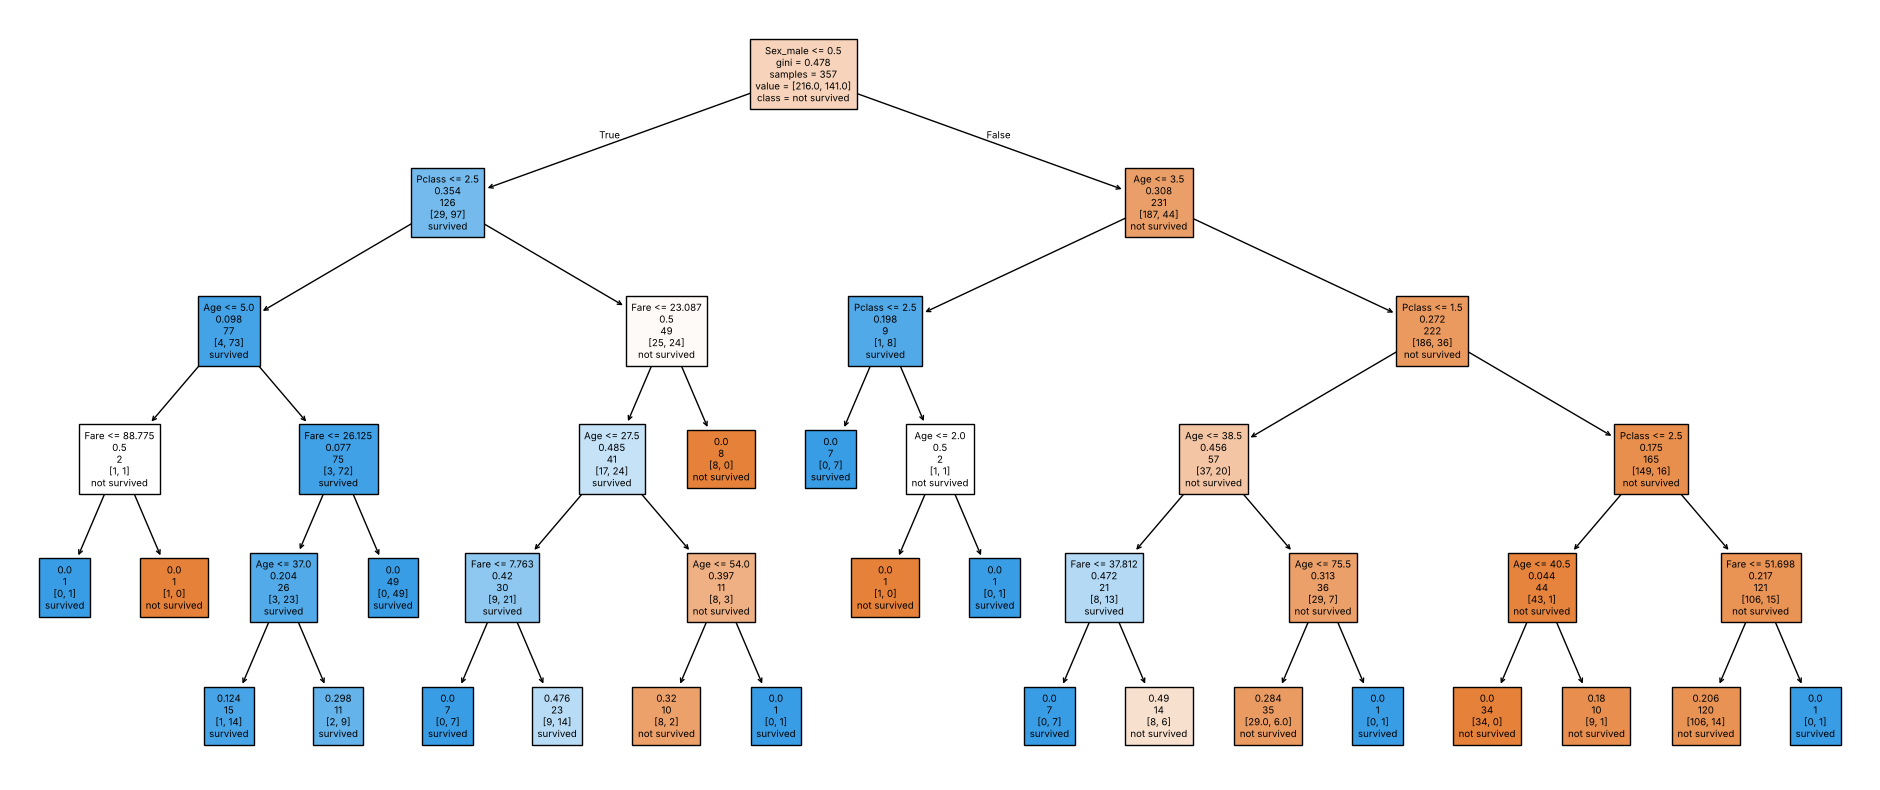

In [14]:
# For the meaning of numbers in boxes see root node
fig = plt.figure(figsize=(24,10))
tree_plot = tree.plot_tree(clf, 
                   feature_names=list(X_train.columns),  
                   class_names=['not survived', 'survived'],
                   filled=True,
                   fontsize=7,
                   label='root')

### Aufgabe 1c: Einfluss von max_depth

In [15]:
# Einfluss von max_depth auf Baumgrösse und Genauigkeit (50/50-Aufteilung wie oben)
rows = []
for d in [2, 3, 5, 10, None]:
    m = DecisionTreeClassifier(random_state=20, max_depth=d).fit(X_train, y_train)
    rows.append({'max_depth': str(d),
                 'Anzahl Blätter': m.get_n_leaves(),
                 'Accuracy Train': m.score(X_train, y_train),
                 'Accuracy Test': m.score(X_test, y_test)})
pd.DataFrame(rows).round(3)

,max_depth,Anzahl Blätter,Accuracy Train,Accuracy Test
0,2,4,0.818,0.787
1,3,8,0.838,0.779
2,5,21,0.885,0.796
3,10,64,0.955,0.801
4,None,89,0.994,0.773


**Antwort Aufgabe 1c (max_depth, Textdarstellung und Grafik):**

Der Parameter max_depth wurde von 3 auf 5 erhöht.

- **Erster Split:** Der Baum teilt zuerst nach 'Sex_male'. Das Geschlecht ist die wichtigste Variable, um zu trennen, wer überlebt hat (Frauen überlebten deutlich häufiger).
- **Weitere Splits:** Bei den Frauen folgt 'Pclass' (Frauen in der 3. Klasse hatten ein deutlich höheres Risiko), bei den Männern 'Age' (sehr junge Knaben überlebten häufiger). Danach folgen 'Fare' und weitere Altersgrenzen.
- **Baumgrösse:** Mit max_depth=5 hat der Baum 21 Blätter, mit max_depth=3 nur 8. Die Grafik und die Textdarstellung werden entsprechend grösser und schwerer lesbar.
- **Overfitting:** Die Accuracy auf den Trainingsdaten steigt mit der Tiefe stark an (0.82 bei Tiefe 2, 0.99 ohne Begrenzung). Die Accuracy auf den Testdaten bleibt dagegen etwa bei 0.77 bis 0.80. Ein unbegrenzter Baum (89 Blätter) lernt die Trainingsdaten praktisch auswendig und ist auf den Testdaten schlechter (0.773) als ein mittelgrosser Baum.
- **Splits ohne Wirkung:** In tiefen Ästen führen manche Splits auf beiden Seiten zur gleichen Klasse (z.B. 'Age <= 37' und 'Age > 37' beide 'class: 1'). Diese Splits verändern die Vorhersage nicht und machen den Baum nur komplizierter.
- **Fazit:** Ein flacher bis mittlerer Baum ist besser interpretierbar und generalisiert ähnlich gut oder besser.

## Random Forest Classifier
For details see: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

### Create train and test samples (train = 80%, test = 20% of the data)
Die Variablen 'Age' und 'Sex_male' wurden entfernt (Aufgabe 1d).

In [16]:
# Create train and test samples
X2_train, X2_test, y2_train, y2_test = train_test_split(df_titanic[['Pclass',
                                                                    'Fare']], 
                                                        df_titanic['Survived'], 
                                                        test_size=0.20, 
                                                        random_state=42)

# Show X2_train
print('X2_train:')
print(X2_train.head(), '\n')

# Show y2_train
print('y2_train:')
print(y2_train.head())

X2_train:
     Pclass     Fare
328       3  20.5250
73        3  14.4542
253       3  16.1000
719       3   7.7750
666       2  13.0000 

y2_train:
328    1
73     0
253    0
719    0
666    0
Name: Survived, dtype: int64


### Fit the Random Forest Classifier

In [17]:
# Initialize the random forest classifier
rfc = RandomForestClassifier(random_state=20, max_depth=10)

# Train the random forest classifier
rfc = rfc.fit(X2_train, y2_train)

# Predict the target variable (0 = not survived, 1 = survived)
y_pred_rf = rfc.predict(X2_test)

print('Predicted target variable (0 = not survived, 1 = survived)')
y_pred_rf

Predicted target variable (0 = not survived, 1 = survived)


array([0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

### Show confusion matrix and classification report

In [18]:
# Confusion matrix
print('Confusion matrix')
print(confusion_matrix(y2_test, y_pred_rf), '\n')

# Classification report
print('Classification report')
print(classification_report(y2_test, y_pred_rf))

Confusion matrix
[[70 17]
 [28 28]] 

Classification report
              precision    recall  f1-score   support

           0       0.71      0.80      0.76        87
           1       0.62      0.50      0.55        56

    accuracy                           0.69       143
   macro avg       0.67      0.65      0.66       143
weighted avg       0.68      0.69      0.68       143



### Show feature importance

Index(['Fare', 'Pclass'], dtype='str')
[0.86079732 0.13920268]


<Axes: ylabel='features'>

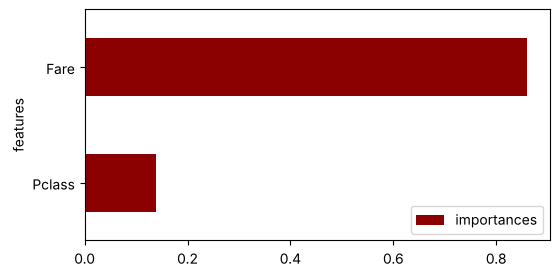

In [19]:
cols = X2_train.columns

# Derive feature importance from random forest
importances = rfc.feature_importances_
std = np.std([tree.feature_importances_ for tree in rfc.estimators_], axis=0)
indices = np.argsort(importances)[::-1]

# Print col-names and importances-values
print( cols[indices] )
print( importances[indices] )

# Barplot with feature importance
df_fi = pd.DataFrame({'features':cols,'importances': importances})
df_fi.sort_values('importances', inplace=True)
df_fi.plot(kind='barh', 
           y='importances', 
           x='features', 
           color='darkred', 
           figsize=(6,3))

### Aufgabe 1d: Feature Importance mit und ohne 'Age' und 'Sex_male'

In [20]:
# Feature Importance: alle 4 Variablen vs. ohne 'Age' und 'Sex_male'
fi = {}
for name, feats in {'Alle Variablen': ['Age', 'Sex_male', 'Pclass', 'Fare'],
                    'Ohne Age und Sex_male': ['Pclass', 'Fare']}.items():
    Xtr, Xte, ytr, yte = train_test_split(df_titanic[feats], df_titanic['Survived'],
                                          test_size=0.20, random_state=42)
    m = RandomForestClassifier(random_state=20, max_depth=10).fit(Xtr, ytr)
    fi[name] = pd.Series(m.feature_importances_, index=feats)
print(pd.DataFrame(fi).round(3))

          Alle Variablen  Ohne Age und Sex_male
Age                0.298                    NaN
Fare               0.270                  0.861
Pclass             0.104                  0.139
Sex_male           0.328                    NaN


**Antwort Aufgabe 1d (Feature Importance):**

| Variable | Mit allen Variablen | Ohne 'Age' und 'Sex_male' |
|---|---|---|
| Sex_male | 0.328 | entfernt |
| Age | 0.298 | entfernt |
| Fare | 0.270 | 0.861 |
| Pclass | 0.104 | 0.139 |

- Mit allen vier Variablen ist 'Sex_male' am wichtigsten, gefolgt von 'Age' und 'Fare'.
- Nach dem Entfernen von 'Age' und 'Sex_male' ist **'Fare' (Ticketpreis) die wichtigste Variable** (ca. 86 %), 'Pclass' folgt mit ca. 14 %.
- 'Fare' übernimmt einen Grossteil der Wichtigkeit, weil die Variable mit der Passagierklasse und dem sozialen Status zusammenhängt und zusätzlich fein abgestuft (stetig) ist. Dadurch bietet sie dem Random Forest viele mögliche Split Punkte. 'Pclass' hat nur drei Werte.

### ROC curve and AUC

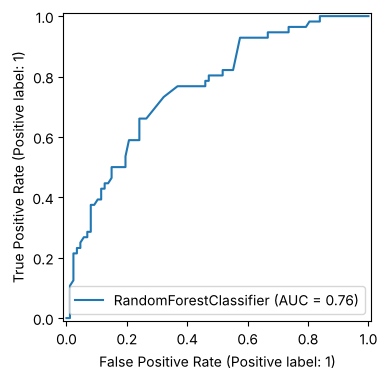

In [21]:
# Plot ROC curve and calculate AUC
plt.figure(figsize=(6,4))
ax = plt.gca()
rfc_disp = RocCurveDisplay.from_estimator(rfc, 
                                          X2_test, 
                                          y2_test, 
                                          ax=ax)
plt.show()

### Aufgabe 1e: ROC-Kurve und AUC mit und ohne 'Age' und 'Sex_male'

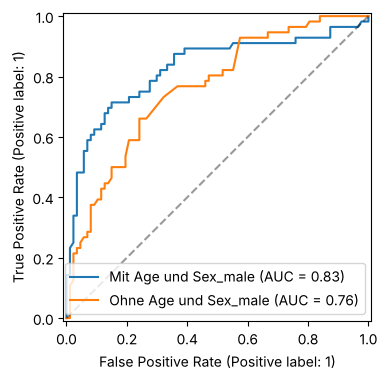

,Modell,AUC,Accuracy
0,Mit Age und Sex_male,0.826,0.783
1,Ohne Age und Sex_male,0.761,0.685


In [22]:
# ROC-Kurven und AUC beider Random Forest Modelle im Vergleich
from sklearn.metrics import roc_auc_score
res = []
plt.figure(figsize=(6,4))
ax = plt.gca()
for (name, feats), col in zip({'Mit Age und Sex_male': ['Age', 'Sex_male', 'Pclass', 'Fare'],
                               'Ohne Age und Sex_male': ['Pclass', 'Fare']}.items(),
                              ['steelblue', 'darkred']):
    Xtr, Xte, ytr, yte = train_test_split(df_titanic[feats], df_titanic['Survived'],
                                          test_size=0.20, random_state=42)
    m = RandomForestClassifier(random_state=20, max_depth=10).fit(Xtr, ytr)
    RocCurveDisplay.from_estimator(m, Xte, yte, ax=ax, name=name)
    res.append({'Modell': name, 'AUC': roc_auc_score(yte, m.predict_proba(Xte)[:, 1]), 'Accuracy': m.score(Xte, yte)})
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.show()
pd.DataFrame(res).round(3)

**Antwort Aufgabe 1e (ROC Kurve und AUC):**

| Modell | AUC | Accuracy |
|---|---|---|
| Mit 'Age' und 'Sex_male' | 0.826 | 0.783 |
| Ohne 'Age' und 'Sex_male' | 0.761 | 0.685 |

- Die ROC Kurve des Modells ohne 'Age' und 'Sex_male' liegt tiefer und näher an der Diagonalen (Zufallsmodell). Das Modell trennt Überlebende und Nicht Überlebende also schlechter.
- Die AUC sinkt von 0.826 auf 0.761, die Accuracy von 0.783 auf 0.685.
- Besonders 'Sex_male' ist ein sehr starker Prädiktor für das Überleben. Ohne diese Variable (und ohne 'Age') verliert das Modell deutlich an Vorhersagequalität.

### Jupyter notebook --footer info-- (please always provide this at the end of each submitted notebook)

In [23]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.18.44-fc-v445
Datetime: 2026-11-13 20:22:36
Python Version: 3.12.3
-----------------------------------
